In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression


pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [38]:
client = pd.read_csv("Client.csv")
record = pd.read_csv("Record.csv")

print("Client dataset shape:", client.shape)
print("Record dataset shape:", record.shape)

display(client.head())
display(record.head())

Client dataset shape: (100000, 50)
Record dataset shape: (100000, 51)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [39]:
print("Client dataset information:")
client.info()

print("\nRecord dataset information:")
record.info()

print("\nMissing values in Client:")
display(client.isnull().sum().sort_values(ascending=False).head(15))

print("\nMissing values in Record:")
display(record.isnull().sum().sort_values(ascending=False).head(15))

Client dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  str    
 3   crclscod          100000 non-null  str    
 4   asl_flag          100000 non-null  str    
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16  avg3

numbcars            49366
dwllsize            38308
HHstatin            37923
ownrent             33706
dwlltype            31909
lor                 30190
income              25436
adults              23019
infobase            22079
hnd_webcap          10189
prizm_social_one     7388
avg6qty              2839
avg6mou              2839
avg6rev              2839
truck                1732
dtype: int64


Missing values in Record:


change_mou       891
change_rev       891
rev_Mean         357
totmrc_Mean      357
mou_Mean         357
da_Mean          357
ovrmou_Mean      357
vceovr_Mean      357
ovrrev_Mean      357
roam_Mean        357
datovr_Mean      357
drop_vce_Mean      0
drop_dat_Mean      0
blck_vce_Mean      0
blck_dat_Mean      0
dtype: int64

In [40]:
def missing_values_report(data, dataset_name):
    missing = data.isnull().sum()

    report = pd.DataFrame({
        "Missing_Count": missing,
        "Missing_Percentage": (missing / len(data) * 100).round(2)
    })

    report = report[report["Missing_Count"] > 0]
    report = report.sort_values(
        by="Missing_Percentage",
        ascending=False
    )

    print(f"\n{dataset_name}: Missing Values Report")
    display(report.head(20))


missing_values_report(client, "Client Dataset")
missing_values_report(record, "Record Dataset")


Client Dataset: Missing Values Report


,Missing_Count,Missing_Percentage
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19
income,25436,25.44
adults,23019,23.02
infobase,22079,22.08
hnd_webcap,10189,10.19



Record Dataset: Missing Values Report


,Missing_Count,Missing_Percentage
change_mou,891,0.89
change_rev,891,0.89
rev_Mean,357,0.36
totmrc_Mean,357,0.36
mou_Mean,357,0.36
da_Mean,357,0.36
ovrmou_Mean,357,0.36
vceovr_Mean,357,0.36
ovrrev_Mean,357,0.36
roam_Mean,357,0.36


In [41]:
df = record.merge(
    client,
    on="Customer_ID",
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", df.shape)
print("\nDuplicate customer IDs:", df["Customer_ID"].duplicated().sum())

print("\nChurn distribution:")
display(
    df["churn"]
    .value_counts()
    .rename(index={0: "Stayed", 1: "Churned"})
    .to_frame("Customer_Count")
)

print("\nChurn percentages:")
display(
    (df["churn"].value_counts(normalize=True) * 100)
    .rename(index={0: "Stayed", 1: "Churned"})
    .round(2)
    .to_frame("Percentage")
)

Merged dataset shape: (100000, 100)

Duplicate customer IDs: 0

Churn distribution:


,Customer_Count
churn,
Stayed,50438
Churned,49562



Churn percentages:


,Percentage
churn,
Stayed,50.44
Churned,49.56


eqpdays        rev_Mean        months       
               mean median     mean median   mean median
Stayed (0)   363.28  310.0    59.22  48.88  18.63   16.0
Churned (1)  421.09  366.0    58.21  47.49  19.04   17.0

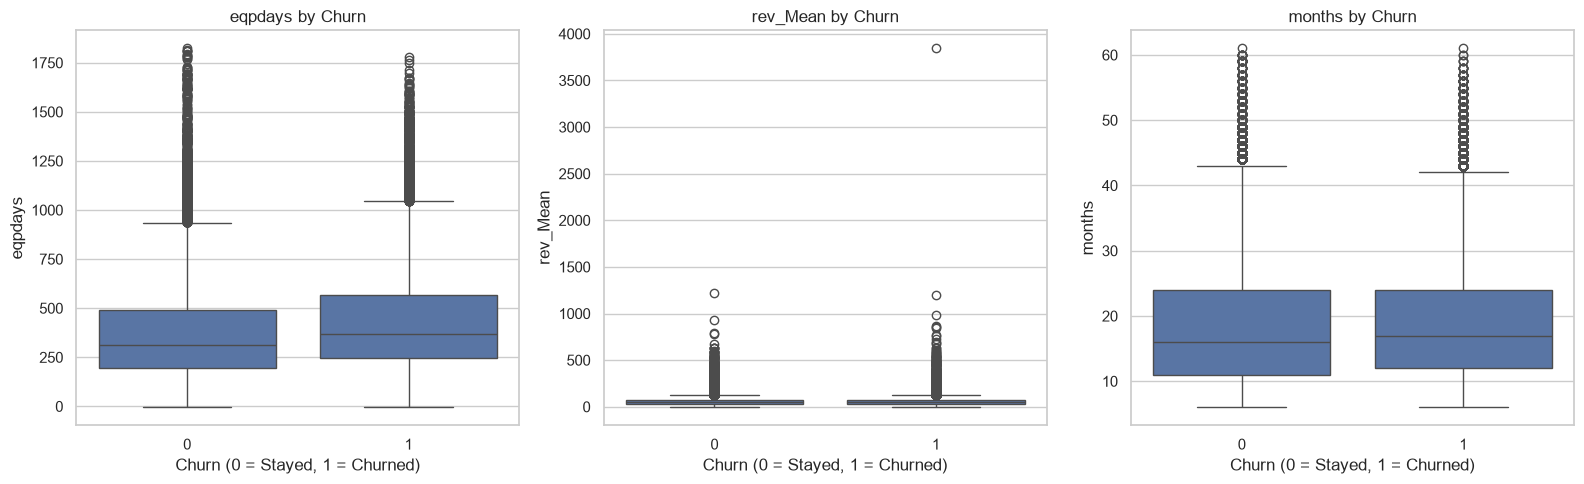

In [42]:

features = ["eqpdays", "rev_Mean", "months"]

summary = df.groupby("churn")[features].agg(["mean", "median"]).round(2)

summary.index = ["Stayed (0)", "Churned (1)"]

display(summary)


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="churn",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Churn")
    ax.set_xlabel("Churn (0 = Stayed, 1 = Churned)")

plt.tight_layout()
plt.show()

,churn_rate,customers
equipment_group,,
Under 180 days,41.74,18327
180–365 days,46.97,36356
365–540 days,53.71,21138
Over 540 days,55.77,24178


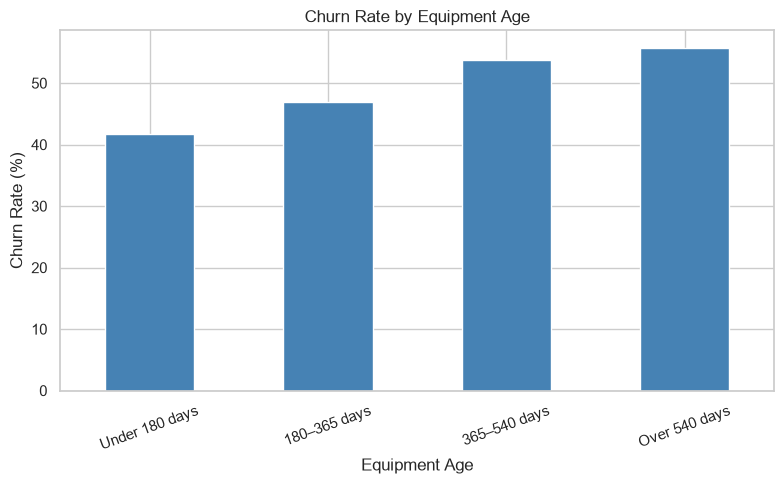

In [43]:
df["equipment_group"] = pd.cut(
    df["eqpdays"],
    bins=[-float("inf"), 180, 365, 540, float("inf")],
    labels=["Under 180 days", "180–365 days", "365–540 days", "Over 540 days"]
)

equipment_churn = (
    df.groupby("equipment_group", observed=False)["churn"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "churn_rate", "count": "customers"})
)

equipment_churn["churn_rate"] = (
    equipment_churn["churn_rate"] * 100
).round(2)

display(equipment_churn)

equipment_churn["churn_rate"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Churn Rate by Equipment Age")
plt.xlabel("Equipment Age")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

,mean,median
Stayed,1.98,0.0
Churned,1.60,0.0


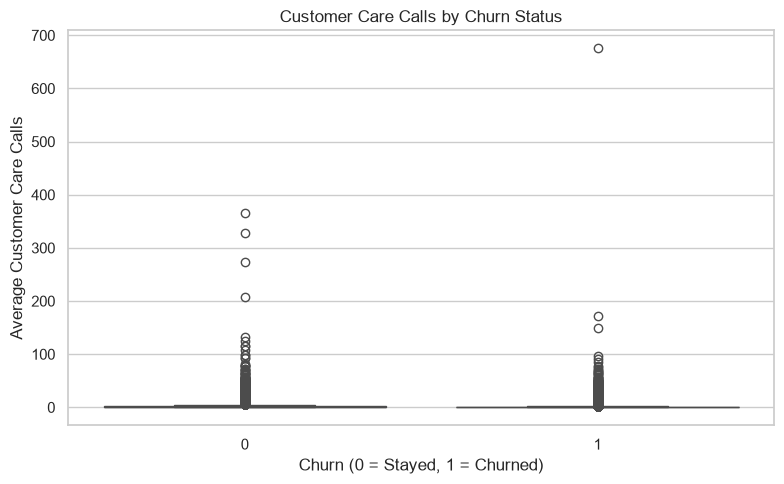

In [44]:
care_summary = df.groupby("churn")["custcare_Mean"].agg(
    ["mean", "median"]
).round(2)

care_summary.index = ["Stayed", "Churned"]

display(care_summary)

# Compare distributions
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn",
    y="custcare_Mean"
)

plt.title("Customer Care Calls by Churn Status")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Average Customer Care Calls")

plt.tight_layout()
plt.show()

In [45]:
print("Dataset shape:", df.shape)

print("\nTarget values:")
print(df["churn"].value_counts(dropna=False))

print("\nNumeric columns:", len(df.select_dtypes(include="number").columns))
print("Categorical columns:", len(df.select_dtypes(include=["object", "category", "str"]).columns))

print("\nTarget missing values:", df["churn"].isna().sum())

print("\nColumns with most missing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("Missing_Count")
)

Dataset shape: (100000, 101)

Target values:
churn
0    50438
1    49562
Name: count, dtype: int64

Numeric columns: 79
Categorical columns: 22

Target missing values: 0

Columns with most missing values:


,Missing_Count
numbcars,49366
dwllsize,38308
HHstatin,37923
ownrent,33706
dwlltype,31909
lor,30190
income,25436
adults,23019
infobase,22079
hnd_webcap,10189


In [46]:
print("Target column: churn")
print("Customer ID available:", "Customer_ID" in df.columns)
print("Temporary analysis column available:", "equipment_group" in df.columns)

print("\nColumns containing churn-related names:")
display([col for col in df.columns if "churn" in col.lower()])

print("\nPotential identifier columns:")
display([col for col in df.columns if "id" in col.lower()])

Target column: churn
Customer ID available: True
Temporary analysis column available: True

Columns containing churn-related names:


['churn']


Potential identifier columns:


['Customer_ID', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17']

In [47]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Percentage"] > 30
].sort_values("Missing_Percentage", ascending=False)

display(missing_report)

,Missing_Count,Missing_Percentage
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19


In [48]:
columns_to_check = [
    "numbcars",
    "dwllsize",
    "HHstatin",
    "ownrent",
    "dwlltype",
    "lor"
]

display(df[columns_to_check].dtypes.to_frame("Data_Type"))

,Data_Type
numbcars,float64
dwllsize,str
HHstatin,str
ownrent,str
dwlltype,str
lor,float64


In [49]:
X_check = df.drop(
    columns=["churn", "Customer_ID", "equipment_group"],
    errors="ignore"
)

constant_columns = [
    col for col in X_check.columns
    if X_check[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

print("Number of features before preprocessing:", X_check.shape[1])

Constant columns: []
Number of features before preprocessing: 98


In [50]:
X = df.drop(
    columns=["churn", "Customer_ID", "equipment_group"],
    errors="ignore"
)

y = df["churn"].astype(int)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Numerical features: 77
Categorical features: 21

Training samples: 80000
Testing samples: 20000


In [51]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


Model Evaluation
------------------------------
Accuracy:  0.5965
Precision: 0.5923
Recall:    0.5964
F1-score:  0.5944
ROC-AUC:   0.6310

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60     10088
           1       0.59      0.60      0.59      9912

    accuracy                           0.60     20000
   macro avg       0.60      0.60      0.60     20000
weighted avg       0.60      0.60      0.60     20000



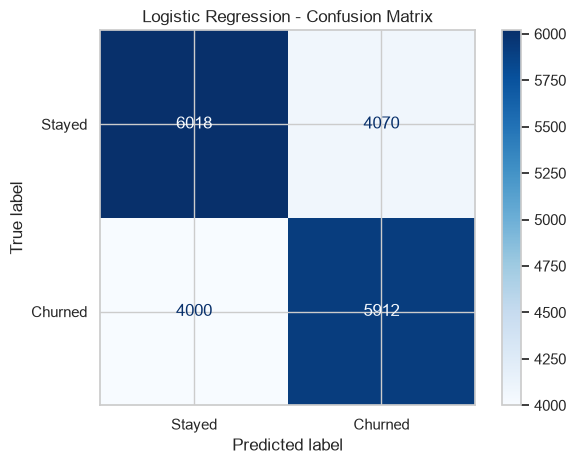

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Model Evaluation")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

numeric_cols = X_train.select_dtypes(include=["number"]).columns
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1-score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_proba)
}

display(pd.DataFrame([rf_results]).round(4))

C:\Users\Engineer Saeid\AppData\Local\Temp\ipykernel_16808\643064495.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.6205,0.6082,0.6582,0.6322,0.6743


,Feature,Importance
76,num__eqpdays,0.0597
48,num__months,0.0483
9,num__change_mou,0.0309
1,num__mou_Mean,0.0244
54,num__adjrev,0.0235
53,num__totrev,0.0223
2,num__totmrc_Mean,0.0210
59,num__avgqty,0.0201
57,num__avgrev,0.0196
10,num__change_rev,0.0193


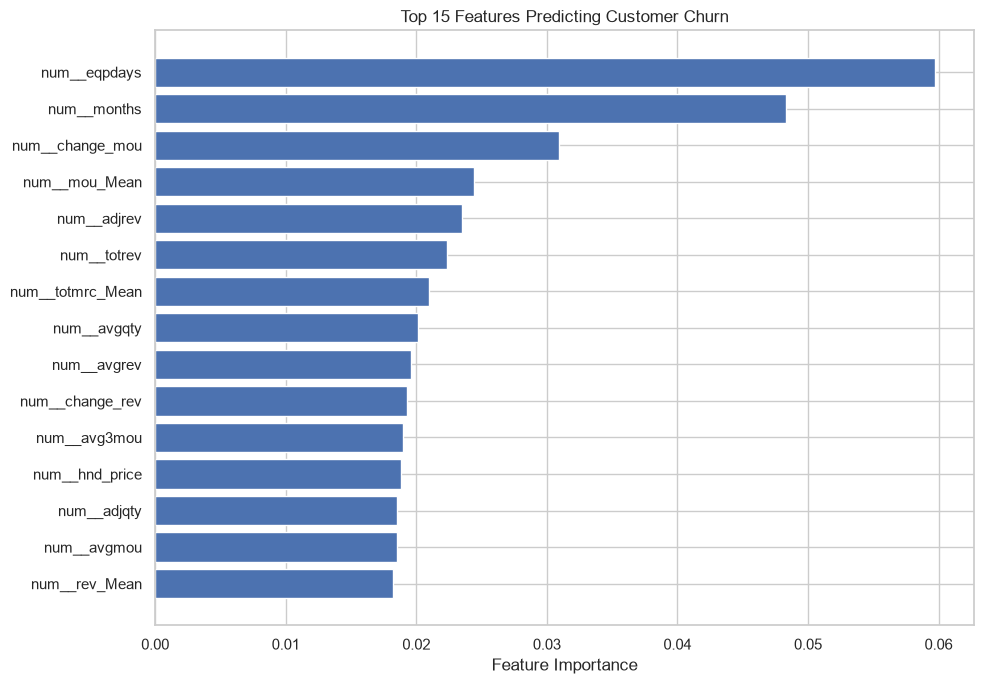

In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features Predicting Customer Churn")
plt.tight_layout()
plt.show()

In [56]:
analysis_df = df[["eqpdays", "churn"]].dropna().copy()

analysis_df["equipment_group"] = pd.cut(
    analysis_df["eqpdays"],
    bins=[-float("inf"), 180, 365, 730, float("inf")],
    labels=["0-180 days", "181-365 days",
            "366-730 days", "Over 730 days"]
)

equipment_analysis = (
    analysis_df.groupby("equipment_group", observed=False)
    .agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

equipment_analysis["churn_rate"] *= 100

display(equipment_analysis.round(2))

,equipment_group,customers,churn_rate
0,0-180 days,18327,41.74
1,181-365 days,36356,46.97
2,366-730 days,34505,53.84
3,Over 730 days,10811,57.89


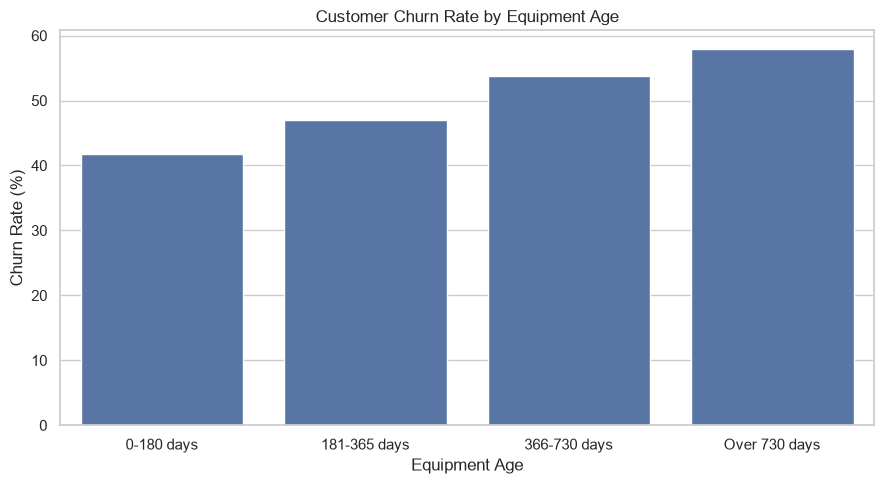

In [57]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=equipment_analysis,
    x="equipment_group",
    y="churn_rate"
)

plt.xlabel("Equipment Age")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Equipment Age")
plt.tight_layout()
plt.show()

In [58]:
tenure_df = df[["months", "churn"]].dropna().copy()

tenure_df["tenure_group"] = pd.cut(
    tenure_df["months"],
    bins=[-float("inf"), 6, 12, 24, 36, 48, float("inf")],
    labels=["0-6", "7-12", "13-24",
            "25-36", "37-48", "Over 48"]
)

tenure_analysis = (
    tenure_df.groupby("tenure_group", observed=False)
    .agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

tenure_analysis["churn_rate"] *= 100

display(tenure_analysis.round(2))

,tenure_group,customers,churn_rate
0,0-6,1295,38.38
1,7-12,31148,47.13
2,13-24,42868,51.78
3,25-36,19024,49.99
4,37-48,4591,48.12
5,Over 48,1074,43.76


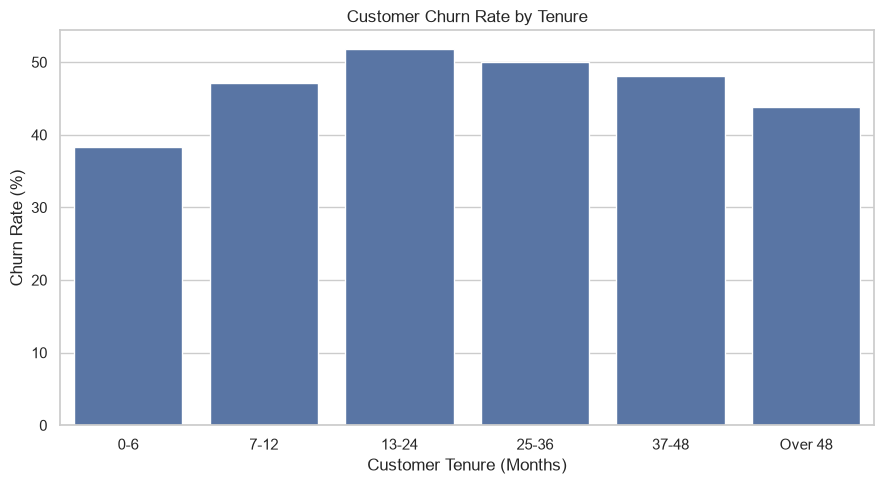

In [59]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_analysis,
    x="tenure_group",
    y="churn_rate"
)

plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Tenure")
plt.tight_layout()
plt.show()

In [60]:
risk_df = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "churn_probability": rf_proba
})

risk_df = risk_df.sort_values(
    "churn_probability", ascending=False
).reset_index(drop=True)

# Select the 10% highest-risk customers
top_n = int(len(risk_df) * 0.10)
top_risk = risk_df.head(top_n)

print("Customers in test set:", len(risk_df))
print("Customers targeted:", len(top_risk))
print(
    "Churn rate in targeted group:",
    round(top_risk["actual_churn"].mean() * 100, 2), "%"
)

Customers in test set: 20000
Customers targeted: 2000
Churn rate in targeted group: 75.75 %


In [61]:
total_churners = risk_df["actual_churn"].sum()
captured_churners = top_risk["actual_churn"].sum()

capture_rate = (
    captured_churners / total_churners * 100
    if total_churners else 0
)

print(f"Actual churners in test set: {total_churners}")
print(f"Churners in top 10% group: {captured_churners}")
print(f"Share of churners captured: {capture_rate:.2f}%")

Actual churners in test set: 9912
Churners in top 10% group: 1515
Share of churners captured: 15.28%


In [ ]:
targeting_results = []

for percentage in [0.10, 0.20, 0.30]:
    n = int(len(risk_df) * percentage)
    targeted = risk_df.head(n)

    targeting_results.append({
        "Targeted (%)": int(percentage * 100),
        "Customers": n,
        "Actual Churners": int(targeted["actual_churn"].sum()),
        "Churn Rate (%)": round(
            targeted["actual_churn"].mean() * 100, 2
        ),
        "Churners Captured (%)": round(
            targeted["actual_churn"].sum()
            / risk_df["actual_churn"].sum() * 100, 2
        )
    })

targeting_comparison = pd.DataFrame(targeting_results)
display(targeting_comparison)

,Targeted (%),Customers,Actual Churners,Churn Rate (%),Churners Captured (%)
0,10,2000,1515,75.75,15.28
1,20,4000,2805,70.12,28.30
2,30,6000,4032,67.20,40.68


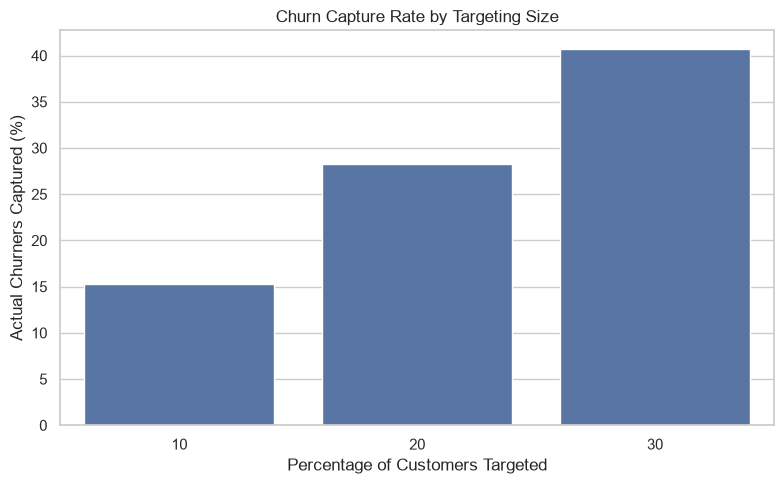

In [63]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=targeting_comparison,
    x="Targeted (%)",
    y="Churners Captured (%)"
)

plt.xlabel("Percentage of Customers Targeted")
plt.ylabel("Actual Churners Captured (%)")
plt.title("Churn Capture Rate by Targeting Size")
plt.tight_layout()
plt.show()

In [65]:
assumed_success_rates = [0.10, 0.20, 0.30]

business_impact = targeting_comparison.copy()

for rate in assumed_success_rates:
    business_impact[f"Potentially Retained ({int(rate*100)}% success)"] = (
        business_impact["Actual Churners"] * rate
    ).round().astype(int)

display(business_impact)

,Targeted (%),Customers,Actual Churners,Churn Rate (%),Churners Captured (%),Potentially Retained (10% success),Potentially Retained (20% success),Potentially Retained (30% success)
0,10,2000,1515,75.75,15.28,152,303,454
1,20,4000,2805,70.12,28.30,280,561,842
2,30,6000,4032,67.20,40.68,403,806,1210


In [67]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

extra_trees = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

extra_trees_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", extra_trees)
])

extra_trees_pipeline.fit(X_train, y_train)

et_pred = extra_trees_pipeline.predict(X_test)
et_proba = extra_trees_pipeline.predict_proba(X_test)[:, 1]

print("Extra Trees Results")
print("Accuracy:", round(accuracy_score(y_test, et_pred), 4))
print("Precision:", round(precision_score(y_test, et_pred), 4))
print("Recall:", round(recall_score(y_test, et_pred), 4))
print("F1-score:", round(f1_score(y_test, et_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, et_proba), 4))

Extra Trees Results
Accuracy: 0.5896
Precision: 0.5852
Recall: 0.5904
F1-score: 0.5878
ROC-AUC: 0.6247


In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns

preprocessor_hgb = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical_cols)
])

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numeric columns: 77
Categorical columns: 21


In [70]:
hgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_hgb),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

hgb_pipeline.fit(X_train, y_train)

hgb_pred = hgb_pipeline.predict(X_test)
hgb_proba = hgb_pipeline.predict_proba(X_test)[:, 1]

print("HistGradientBoosting Results")
print("Accuracy:", round(accuracy_score(y_test, hgb_pred), 4))
print("Precision:", round(precision_score(y_test, hgb_pred), 4))
print("Recall:", round(recall_score(y_test, hgb_pred), 4))
print("F1-score:", round(f1_score(y_test, hgb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, hgb_proba), 4))

HistGradientBoosting Results
Accuracy: 0.6343
Precision: 0.6263
Recall: 0.65
F1-score: 0.638
ROC-AUC: 0.688


In [71]:
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

print("\nPotential leakage columns:")
print([
    col for col in X_train.columns
    if any(term in col.lower() for term in [
        "customer_id", "churn", "temporary", "target"
    ])
])

Training features: 98
Testing features: 98

Potential leakage columns:
[]


In [72]:
hgb_proba = hgb_pipeline.predict_proba(X_test)[:, 1]

risk_df_hgb = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "churn_probability": hgb_proba
}).sort_values(
    "churn_probability", ascending=False
).reset_index(drop=True)

top_n = int(len(risk_df_hgb) * 0.10)
top_10 = risk_df_hgb.head(top_n)

total_churners = risk_df_hgb["actual_churn"].sum()
captured_churners = top_10["actual_churn"].sum()

print("Test ROC-AUC:", round(
    roc_auc_score(y_test, hgb_proba), 4
))
print("Customers targeted:", top_n)
print("Actual churners in top 10%:", int(captured_churners))
print("Churn rate in top 10%:", round(
    top_10["actual_churn"].mean() * 100, 2
), "%")
print("Share of test churners captured:", round(
    captured_churners / total_churners * 100, 2
), "%")

Test ROC-AUC: 0.688
Customers targeted: 2000
Actual churners in top 10%: 1564
Churn rate in top 10%: 78.2 %
Share of test churners captured: 15.78 %


In [73]:
hgb_model = hgb_pipeline.named_steps["model"]
hgb_preprocessor = hgb_pipeline.named_steps["preprocessor"]

feature_names = hgb_preprocessor.get_feature_names_out()
importances = hgb_model.feature_importances_ if hasattr(
    hgb_model, "feature_importances_"
) else None

print("Has built-in feature importance:", importances is not None)

Has built-in feature importance: False


In [75]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    hgb_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

,Feature,Importance
48,months,0.0385
97,eqpdays,0.0329
1,mou_Mean,0.0271
9,change_mou,0.0231
73,hnd_price,0.0105
2,totmrc_Mean,0.0102
62,avgqty,0.0071
49,uniqsubs,0.0060
11,drop_vce_Mean,0.0041
90,ethnic,0.0038


In [78]:
tenure_data = df[["months", "churn"]].dropna().copy()

tenure_data["tenure_group"] = pd.cut(
    tenure_data["months"],
    bins=[-float("inf"), 6, 12, 24, 36, 48, float("inf")],
    labels=["0-6", "7-12", "13-24", "25-36", "37-48", "Over 48"]
)

tenure_churn = (
    tenure_data.groupby("tenure_group", observed=True)
    .agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

tenure_churn["churn_rate"] *= 100

display(tenure_churn.round(2))


,tenure_group,customers,churn_rate
0,0-6,1295,38.38
1,7-12,31148,47.13
2,13-24,42868,51.78
3,25-36,19024,49.99
4,37-48,4591,48.12
5,Over 48,1074,43.76


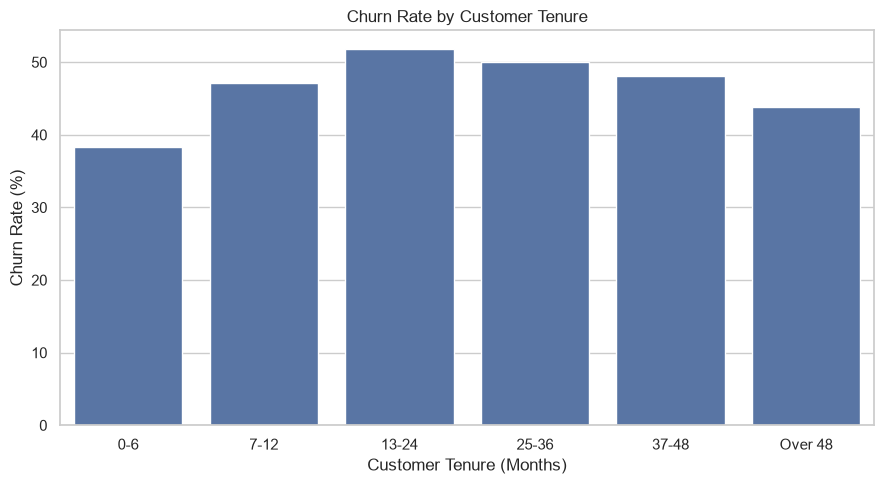

In [79]:
plt.figure(figsize=(9, 5))
sns.barplot(data=tenure_churn, x="tenure_group", y="churn_rate")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Tenure")
plt.tight_layout()
plt.show()

In [80]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nMissing target values:")
print("Train:", y_train.isna().sum())
print("Test:", y_test.isna().sum())

Training rows: 80000
Testing rows: 20000

Training target distribution (%):
churn
0    50.44
1    49.56
Name: proportion, dtype: float64

Testing target distribution (%):
churn
0    50.44
1    49.56
Name: proportion, dtype: float64

Missing target values:
Train: 0
Test: 0


In [81]:
train_ids = set(df.loc[X_train.index, "Customer_ID"])
test_ids = set(df.loc[X_test.index, "Customer_ID"])

print("Overlapping customers:", len(train_ids & test_ids))
print("Unique training customers:", len(train_ids))
print("Unique testing customers:", len(test_ids))

Overlapping customers: 0
Unique training customers: 80000
Unique testing customers: 20000


In [82]:
print("All training features:")
for col in X_train.columns:
    print(col)

All training features:
rev_Mean
mou_Mean
totmrc_Mean
da_Mean
ovrmou_Mean
ovrrev_Mean
vceovr_Mean
datovr_Mean
roam_Mean
change_mou
change_rev
drop_vce_Mean
drop_dat_Mean
blck_vce_Mean
blck_dat_Mean
unan_vce_Mean
unan_dat_Mean
plcd_vce_Mean
plcd_dat_Mean
recv_vce_Mean
recv_sms_Mean
comp_vce_Mean
comp_dat_Mean
custcare_Mean
ccrndmou_Mean
cc_mou_Mean
inonemin_Mean
threeway_Mean
mou_cvce_Mean
mou_cdat_Mean
mou_rvce_Mean
owylis_vce_Mean
mouowylisv_Mean
iwylis_vce_Mean
mouiwylisv_Mean
peak_vce_Mean
peak_dat_Mean
mou_peav_Mean
mou_pead_Mean
opk_vce_Mean
opk_dat_Mean
mou_opkv_Mean
mou_opkd_Mean
drop_blk_Mean
attempt_Mean
complete_Mean
callfwdv_Mean
callwait_Mean
months
uniqsubs
actvsubs
new_cell
crclscod
asl_flag
totcalls
totmou
totrev
adjrev
adjmou
adjqty
avgrev
avgmou
avgqty
avg3mou
avg3qty
avg3rev
avg6mou
avg6qty
avg6rev
prizm_social_one
area
dualband
refurb_new
hnd_price
phones
models
hnd_webcap
truck
rv
ownrent
lor
dwlltype
marital
adults
infobase
income
numbcars
HHstatin
dwllsize
forgntvl

In [83]:
suspicious_terms = [
    "churn", "target", "customer_id",
    "cust_id", "outcome", "label"
]

suspicious_columns = [
    col for col in X_train.columns
    if any(term in col.lower() for term in suspicious_terms)
]

print("Suspicious feature names:", suspicious_columns)
print("Duplicate feature names:", X_train.columns.duplicated().sum())
print("Same train/test feature columns:",
      X_train.columns.equals(X_test.columns))

Suspicious feature names: []
Duplicate feature names: 0
Same train/test feature columns: True


In [85]:
from sklearn.model_selection import RandomizedSearchCV
hgb_search_pipeline = Pipeline([
    ("preprocessor", preprocessor_hgb),
    ("model", HistGradientBoostingClassifier(
        random_state=42
    ))
])

param_distributions = {
    "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "model__max_iter": [100, 150, 200, 250],
    "model__max_leaf_nodes": [7, 15, 31],
    "model__l2_regularization": [0.0, 1.0, 5.0, 10.0]
}

hgb_search = RandomizedSearchCV(
    estimator=hgb_search_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

hgb_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(hgb_search.best_score_, 4))
print("Best parameters:")
print(hgb_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV ROC-AUC: 0.6896
Best parameters:
{'model__max_leaf_nodes': 31, 'model__max_iter': 250, 'model__learning_rate': 0.1, 'model__l2_regularization': 5.0}


In [86]:
best_hgb = hgb_search.best_estimator_

best_pred = best_hgb.predict(X_test)
best_proba = best_hgb.predict_proba(X_test)[:, 1]

print("Tuned HistGradientBoosting Results")
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(precision_score(y_test, best_pred), 4))
print("Recall:", round(recall_score(y_test, best_pred), 4))
print("F1-score:", round(f1_score(y_test, best_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_proba), 4))

# Top 10% highest-risk customers
tuned_risk = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "churn_probability": best_proba
}).sort_values(
    "churn_probability", ascending=False
)

top_10_tuned = tuned_risk.head(int(len(tuned_risk) * 0.10))

print("\nTop 10% targeting")
print("Customers targeted:", len(top_10_tuned))
print("Churn rate (%):", round(
    top_10_tuned["actual_churn"].mean() * 100, 2
))
print("Churners captured (%):", round(
    top_10_tuned["actual_churn"].sum()
    / tuned_risk["actual_churn"].sum() * 100, 2
))

Tuned HistGradientBoosting Results
Accuracy: 0.6379
Precision: 0.6312
Recall: 0.6478
F1-score: 0.6394
ROC-AUC: 0.6923

Top 10% targeting
Customers targeted: 2000
Churn rate (%): 79.1
Churners captured (%): 15.96


In [87]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Top 10% Churn Rate",
        "Top 10% Churners Captured"
    ],
    "Value": [
        accuracy_score(y_test, best_pred),
        precision_score(y_test, best_pred),
        recall_score(y_test, best_pred),
        f1_score(y_test, best_pred),
        roc_auc_score(y_test, best_proba),
        top_10_tuned["actual_churn"].mean(),
        top_10_tuned["actual_churn"].sum()
        / tuned_risk["actual_churn"].sum()
    ]
})

final_results["Value"] = (
    final_results["Value"].round(4)
)

display(final_results)

,Metric,Value
0,Accuracy,0.6379
1,Precision,0.6312
2,Recall,0.6478
3,F1-score,0.6394
4,ROC-AUC,0.6923
5,Top 10% Churn Rate,0.7910
6,Top 10% Churners Captured,0.1596


In [88]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Extra Trees",
        "HistGradientBoosting",
        "Tuned HistGradientBoosting"
    ],
    "Accuracy": [0.5965, 0.6205, 0.5896, 0.6343, 0.6379],
    "F1-score": [0.5944, 0.6322, 0.5878, 0.6380, 0.6394],
    "ROC-AUC": [0.6310, 0.6743, 0.6247, 0.6880, 0.6923]
})

display(model_comparison.sort_values("ROC-AUC", ascending=False))

,Model,Accuracy,F1-score,ROC-AUC
4,Tuned HistGradientBoosting,0.6379,0.6394,0.6923
3,HistGradientBoosting,0.6343,0.6380,0.6880
1,Random Forest,0.6205,0.6322,0.6743
0,Logistic Regression,0.5965,0.5944,0.6310
2,Extra Trees,0.5896,0.5878,0.6247


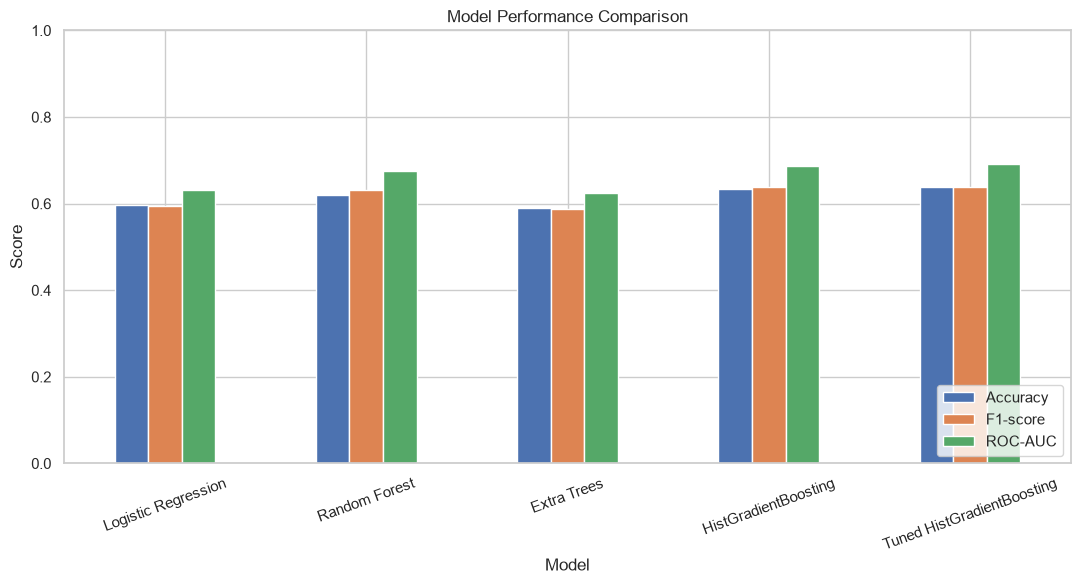

In [89]:
ax = model_comparison.set_index("Model")[["Accuracy", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=20
)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Business Recommendations

1. Identify High-Risk Customers

Use the tuned HistGradientBoosting model to identify customers with a high probability of churn. Prioritize customers with the highest predicted risk for retention campaigns.

2. Focus on Customer Tenure and Equipment Age

The exploratory analysis showed higher churn rates among customers with longer equipment age ("eqpdays") and certain tenure groups. The company should investigate these patterns and consider targeted retention offers.

3. Prioritize Limited Campaign Budgets

The top 10% of customers ranked by predicted churn risk had a churn rate of 79.1% in the test set. This suggests that risk-based targeting may help prioritize retention resources.

4. Test Retention Campaigns

Run a pilot campaign and compare outcomes between contacted customers and a suitable control group. Measure retention, campaign cost, and incremental profit before expanding the campaign.

5. Monitor Model Performance

The tuned model achieved a ROC-AUC of 0.6923. Its performance is moderate, so the company should monitor results, evaluate alternative models, and retrain when customer behavior changes.